### Step 1: Import Libraries and Load Data
We will import the necessary data science and machine learning libraries. Since we have a notebook path `/content/online-retail-k-means-hierarchical-clustering.ipynb` in the workspace, we will search for an online retail dataset online (like the UCI Machine Learning Repository) or check if we can download it directly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Let's download the Online Retail dataset directly from UCI repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx'
print("Downloading dataset (this might take a minute)...")
df = pd.read_excel(url)
print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Step 2: Data Preprocessing and RFM Calculation
We will clean the dataset by removing missing customer IDs and transactions with negative quantities/prices. Then, we will calculate Recency, Frequency, and Monetary (RFM) metrics for each customer.

In [2]:
# Drop rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])
df['CustomerID'] = df['CustomerID'].astype(str)

# Remove cancelled orders and invalid prices/quantities
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Calculate Total Amount
df['Amount'] = df['Quantity'] * df['UnitPrice']

# RFM Analysis
# 1. Monetary (Total amount spent)
monetary = df.groupby('CustomerID')['Amount'].sum().reset_index()

# 2. Frequency (Number of transactions)
frequency = df.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()
frequency.columns = ['CustomerID', 'Frequency']

# 3. Recency (Days since last purchase)
max_date = df['InvoiceDate'].max()
df['Diff'] = max_date - df['InvoiceDate']
recency = df.groupby('CustomerID')['Diff'].min().reset_index()
recency['Diff'] = recency['Diff'].dt.days
recency.columns = ['CustomerID', 'Recency']

# Merge RFM metrics
rfm = monetary.merge(frequency, on='CustomerID').merge(recency, on='CustomerID')
rfm.columns = ['CustomerID', 'Amount', 'Frequency', 'Recency']
display(rfm.head())

,CustomerID,Amount,Frequency,Recency
0,12346.0,77183.60,1,325
1,12347.0,4310.00,7,1
2,12348.0,1797.24,4,74
3,12349.0,1757.55,1,18
4,12350.0,334.40,1,309


### Step 3: Rescale features and find Optimal Clusters via Elbow Method
Since K-Means is sensitive to feature scaling, we will standardize the RFM features. Then, we will plot the Elbow Curve to find the optimal number of segments.

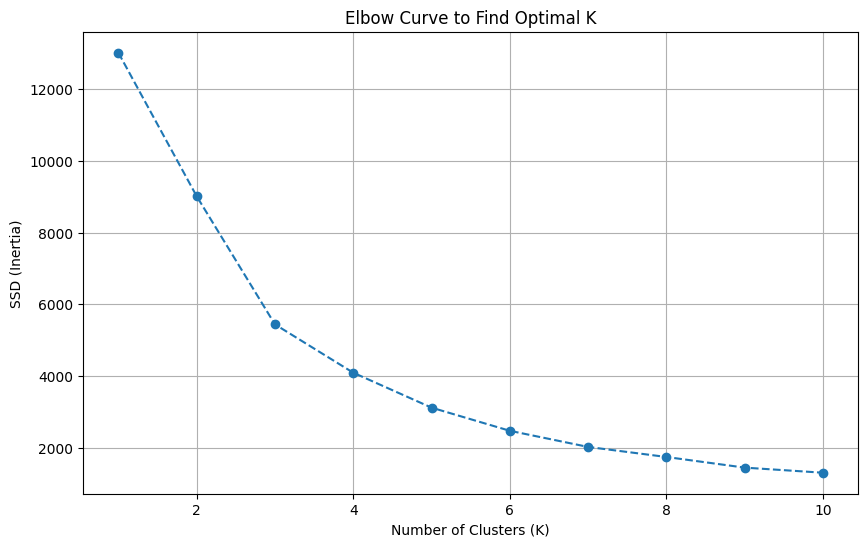

In [3]:
# Scale the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Amount', 'Frequency', 'Recency']])
rfm_scaled = pd.DataFrame(rfm_scaled, columns=['Amount', 'Frequency', 'Recency'])

# Elbow Curve (SSD - Sum of Squared Distances)
ssd = []
range_n_clusters = list(range(1, 11))

for num_clusters in range_n_clusters:
    kmeans = KMeans(n_clusters=num_clusters, max_iter=50, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    ssd.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(10, 6))
plt.plot(range_n_clusters, ssd, marker='o', linestyle='--')
plt.title('Elbow Curve to Find Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('SSD (Inertia)')
plt.grid(True)
plt.show()

### Step 4: Fit K-Means Model
Based on the Elbow Curve, choose the optimal number of clusters (typically 3 or 4) to segment your customers.

In [4]:
# Choose the optimal number of clusters (e.g., K=3)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, max_iter=100, random_state=42, n_init=10)
k_labels = kmeans.fit_predict(rfm_scaled)

# Assign the cluster labels back to our RFM dataset
rfm['Cluster'] = k_labels

# Summary stats for each cluster
cluster_summary = rfm.groupby('Cluster').agg({
    'Amount': 'mean',
    'Frequency': 'mean',
    'Recency': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Customer Count'}).reset_index()

display(cluster_summary)

,Cluster,Amount,Frequency,Recency,Customer Count
0,0,631.424206,1.582255,246.106285,1082
1,1,1855.942345,4.672755,40.454180,3230
2,2,85904.351538,66.423077,5.038462,26
